In [10]:
import numpy as np
import os
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle

In [11]:
DATA_PATH = '/content/Dataset'

In [26]:
CLASS_NAMES = os.listdir(DATA_PATH)
x, y = [], []

img_size = 224
counter = 0

for idx, folder_path in enumerate(os.listdir(DATA_PATH)):
    for file_path in os.listdir(f'{DATA_PATH}/{folder_path}'):
        img_path = f'{DATA_PATH}/{folder_path}/{file_path}'

        image = tf.keras.preprocessing.image.load_img(img_path, target_size=(img_size, img_size), color_mode="grayscale")
        image = tf.keras.preprocessing.image.img_to_array(image)

        x.append(image)
        y.append(idx)

print(CLASS_NAMES)

['Cucumber', 'Tomato', 'Broccoli', 'Carrot']


In [13]:
x, y = shuffle(x, y, random_state=42)

In [14]:
x = np.array(x)
y = np.array(y)

x = x.astype('float32') / 255.0

In [15]:
x_train, x_temp, y_train, y_temp = train_test_split(x, y, test_size=0.2, random_state=42)
x_test, x_val, y_test, y_val = train_test_split(x_temp, y_temp, test_size=0.5, random_state=42)

y_train = tf.keras.utils.to_categorical(y_train, num_classes=(len(CLASS_NAMES)))
y_val = tf.keras.utils.to_categorical(y_val, num_classes=(len(CLASS_NAMES)))
y_test = tf.keras.utils.to_categorical(y_test, num_classes=(len(CLASS_NAMES)))

In [31]:
model = tf.keras.Sequential([
    tf.keras.layers.Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=(224, 224, 1)),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(64, kernel_size=(3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(128, kernel_size=(3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(len(CLASS_NAMES), activation='softmax')
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 222, 222, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,168,900 (42.61 MB)

 Trainable params: 11,168,900 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [32]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(0.001),
    loss='categorical_crossentropy',
    metrics=['Accuracy']
)

In [33]:
print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))

Num GPUs Available:  1


In [34]:
history = model.fit(x_train, y_train, epochs=10, batch_size=100, validation_data=(x_val, y_val))

Epoch 1/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 10s 241ms/step - Accuracy: 0.3187 - loss: 1.5125 - val_Accuracy: 0.4750 - val_loss: 1.0800
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 174ms/step - Accuracy: 0.6913 - loss: 0.7697 - val_Accuracy: 0.7650 - val_loss: 0.6359
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 176ms/step - Accuracy: 0.7975 - loss: 0.5082 - val_Accuracy: 0.8100 - val_loss: 0.5638
Epoch 4/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 177ms/step - Accuracy: 0.8744 - loss: 0.3344 - val_Accuracy: 0.8450 - val_loss: 0.5065
Epoch 5/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 178ms/step - Accuracy: 0.8994 - loss: 0.2789 - val_Accuracy: 0.8600 - val_loss: 0.4560
Epoch 6/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 179ms/step - Accuracy: 0.9325 - loss: 0.1950 - val_Accuracy: 0.8950 - val_loss: 0.4143
Epoch 7/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 182ms/step - Accuracy: 0.9513 - loss: 0.1278 - val_Accuracy: 0.8750 - val_loss: 0.4490
Epoch 8/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 183ms/step - Accuracy: 0.9706 - loss: 0.0895 - val_Accuracy: 0

In [35]:
print(history.history.keys())

dict_keys(['Accuracy', 'loss', 'val_Accuracy', 'val_loss'])


In [36]:
evaluate = model.evaluate(x_test, y_test)

print("Loss: ", evaluate[0])
print("Accuracy: ", evaluate[1])

7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 128ms/step - Accuracy: 0.8950 - loss: 0.4502
Loss:  0.450206458568573
Accuracy:  0.8949999809265137


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step


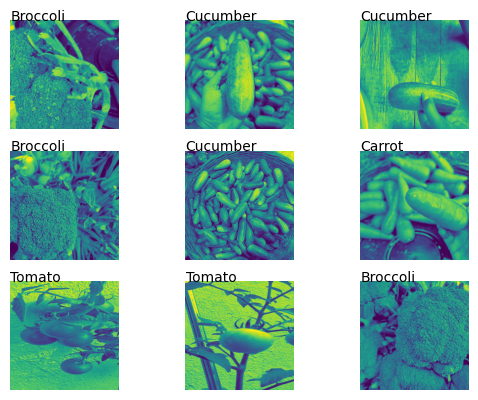

In [40]:
predicted = model.predict(x_test)
predicted_label = np.argmax(predicted, axis=1)

for i in range(9):
    plt.subplot(3, 3, i+1)
    plt.imshow(x_test[i])
    plt.axis('off')
    plt.text(0.5, -0.15, CLASS_NAMES[predicted_label[i]])

[]

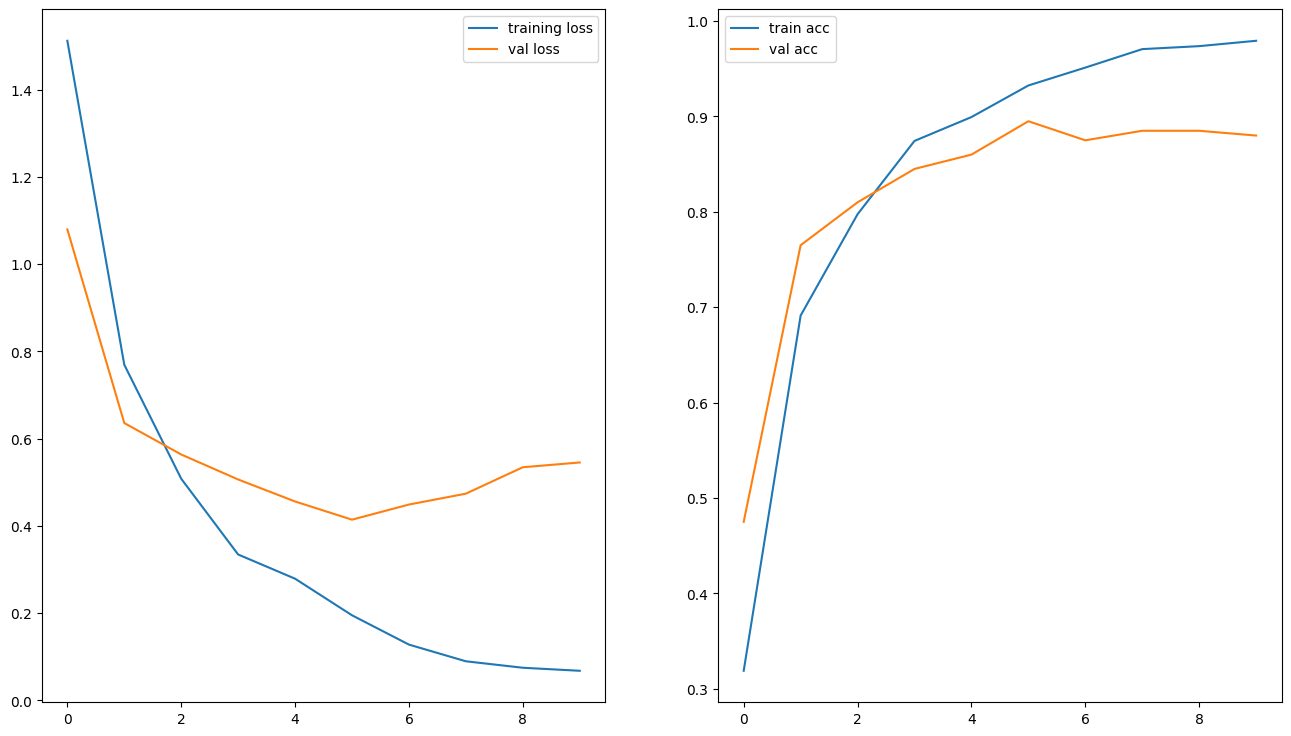

In [41]:
plt.figure(figsize=(16, 9))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label="training loss")
plt.plot(history.history['val_loss'], label="val loss")
plt.xlabel = 'epoch'
plt.ylabel = 'loss'
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['Accuracy'], label="train acc")
plt.plot(history.history['val_Accuracy'], label="val acc")
plt.xlabel = 'epoch'
plt.ylabel = 'loss'
plt.legend()

plt.plot()